# Task 4 — NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Pipeline:** raw reviews → cleaning (lowercase, HTML/punctuation removal, stopwords, lemmatization) → `TfidfVectorizer(max_features=5000)` → `MultinomialNB` and `LogisticRegression` → accuracy benchmarks → `predict_sentiment()` helper.

**Datasets used**
1. `sentiment_reviews` (the 10-row sample from the task brief) — used to demonstrate the pipeline end-to-end. It is far too small for a trustworthy accuracy number.
2. NLTK `movie_reviews` (2,000 labelled reviews) — used for the **real benchmark**, since the brief asks to download a sentiment dataset.

Neutral reviews are dropped because the task is binary (positive vs negative).

In [1]:
import re, html, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

for pkg in ["stopwords", "wordnet", "omw-1.4", "movie_reviews"]:
    nltk.download(pkg, quiet=True)
RANDOM_STATE = 42

## 1. Load the data
The sample from the brief is embedded so the notebook runs anywhere. If you have the Excel/CSV file, set `SAMPLE_PATH` and it will be used instead.

In [2]:
SAMPLE_PATH = "sentiment_reviews.xlsx"   # or .csv; falls back to the embedded sample if not found

embedded = [
 (1,"The product quality is exceptional, exceeded all my expectations!","positive"),
 (2,"Terrible customer service and the item arrived completely damaged.","negative"),
 (3,"Average performance, decent for the price point but nothing special.","neutral"),
 (4,"Absolutely love this! Easy to setup, robust, and works flawlessly.","positive"),
 (5,"Stopped working after two days. Extremely disappointed with the purchase.","negative"),
 (6,"Customer support helped resolve my setup question within ten minutes.","positive"),
 (7,"Delivery was slow and package was missing one adapter cable.","negative"),
 (8,"Clean interface and intuitive controls. Highly recommended for students.","positive"),
 (9,"Not worth the money, plenty of better alternatives available.","negative"),
 (10,"Great value and durable build. Would definitely purchase again.","positive"),
]
import os
if os.path.exists(SAMPLE_PATH):
    sample = pd.read_excel(SAMPLE_PATH) if SAMPLE_PATH.endswith(("xlsx","xls")) else pd.read_csv(SAMPLE_PATH)
    print("Loaded", SAMPLE_PATH)
else:
    sample = pd.DataFrame(embedded, columns=["review_id","review_text","sentiment"])
    print("Using embedded sample from the task brief")
print(sample.shape); print(sample.sentiment.value_counts())
sample.head()

Using embedded sample from the task brief
(10, 3)
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


## 2. Text preprocessing
Steps: lowercase → unescape/strip HTML tags → keep letters only → tokenize → remove stopwords → lemmatize.

> **Design note:** the default NLTK stopword list contains negations (`not`, `no`, `nor`, `don't`, …). Removing them flips the meaning of phrases like *"not worth the money"*, so I deliberately **keep negations**.

In [3]:
STOP = set(stopwords.words("english"))
NEGATIONS = {"not","no","nor","never","n't","don","didn","doesn","isn","wasn","aren","weren","won","wouldn","couldn","shouldn","haven","hasn","hadn"}
STOP -= NEGATIONS
lemmatizer = WordNetLemmatizer()

def preprocess(text: str) -> str:
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)           # HTML tags
    text = re.sub(r"n't\b", " not", text)           # don't -> do not
    text = re.sub(r"[^a-z\s]", " ", text)           # punctuation, digits
    tokens = [t for t in text.split() if t not in STOP and len(t) > 1]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n") for t in tokens]
    return " ".join(tokens)

for s in ["<br />Terrible customer service and the item arrived completely damaged!",
          "Not worth the money, plenty of better alternatives available.",
          "I don't like it. The batteries were dying quickly."]:
    print(s, "\n  ->", preprocess(s), "\n")

<br />Terrible customer service and the item arrived completely damaged! 
  -> terrible customer service item arrive completely damage 

Not worth the money, plenty of better alternatives available. 
  -> not worth money plenty better alternative available 

I don't like it. The batteries were dying quickly. 
  -> not like battery die quickly 



## 3. Pipeline on the brief's sample (10 reviews → 9 after dropping neutral)

In [4]:
df = sample[sample.sentiment.isin(["positive","negative"])].copy()
df["clean"] = df.review_text.apply(preprocess)
df["label"] = (df.sentiment == "positive").astype(int)
display(df[["review_text","clean","sentiment"]])

X_tr, X_te, y_tr, y_te = train_test_split(df.clean, df.label, test_size=0.33, stratify=df.label, random_state=RANDOM_STATE)
for name, clf in [("MultinomialNB", MultinomialNB()), ("LogisticRegression", LogisticRegression(max_iter=1000))]:
    p = Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("clf", clf)]).fit(X_tr, y_tr)
    print(f"{name:20s} accuracy on {len(X_te)} held-out reviews: {accuracy_score(y_te, p.predict(X_te)):.2f}")
print("\n⚠ With only", len(df), "reviews this number is meaningless — see the real benchmark below.")

,review_text,clean,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceed expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrive complete...,negative
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stop work two day extremely disappoint purchase,negative
5,Customer support helped resolve my setup quest...,customer support help resolve setup question w...,positive
6,Delivery was slow and package was missing one ...,delivery slow package miss one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


MultinomialNB        accuracy on 3 held-out reviews: 0.67
LogisticRegression   accuracy on 3 held-out reviews: 0.67

⚠ With only 9 reviews this number is meaningless — see the real benchmark below.


## 4. Real benchmark: NLTK `movie_reviews` (2,000 reviews, balanced)

In [5]:
from nltk.corpus import movie_reviews
docs = [(movie_reviews.raw(fid), cat) for cat in movie_reviews.categories() for fid in movie_reviews.fileids(cat)]
big = pd.DataFrame(docs, columns=["review_text","sentiment"])
big["clean"] = big.review_text.apply(preprocess)
big["label"] = (big.sentiment == "pos").astype(int)
print(big.shape); print(big.sentiment.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    big.clean, big.label, test_size=0.2, stratify=big.label, random_state=RANDOM_STATE)
print(len(X_train), "train /", len(X_test), "test")

(2000, 4)
sentiment
neg    1000
pos    1000
Name: count, dtype: int64
1600 train / 400 test


In [6]:
models = {
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "LogisticRegression": LogisticRegression(max_iter=1000, C=10),
}
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, big.clean, big.label, cv=5, scoring="accuracy")
    fitted[name] = pipe
    rows.append({"model": name, "test_accuracy": accuracy_score(y_test, pred), "cv_mean": cv.mean(), "cv_std": cv.std()})
    print(f"=== {name} ===\n", classification_report(y_test, pred, target_names=["negative","positive"]))
results = pd.DataFrame(rows).round(4); results

=== MultinomialNB ===
               precision    recall  f1-score   support

    negative       0.80      0.84      0.82       200
    positive       0.84      0.80      0.82       200

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400



=== LogisticRegression ===
               precision    recall  f1-score   support

    negative       0.87      0.83      0.85       200
    positive       0.84      0.88      0.86       200

    accuracy                           0.85       400
   macro avg       0.86      0.85      0.85       400
weighted avg       0.86      0.85      0.85       400



,model,test_accuracy,cv_mean,cv_std
0,MultinomialNB,0.820,0.8175,0.0142
1,LogisticRegression,0.855,0.8540,0.0116


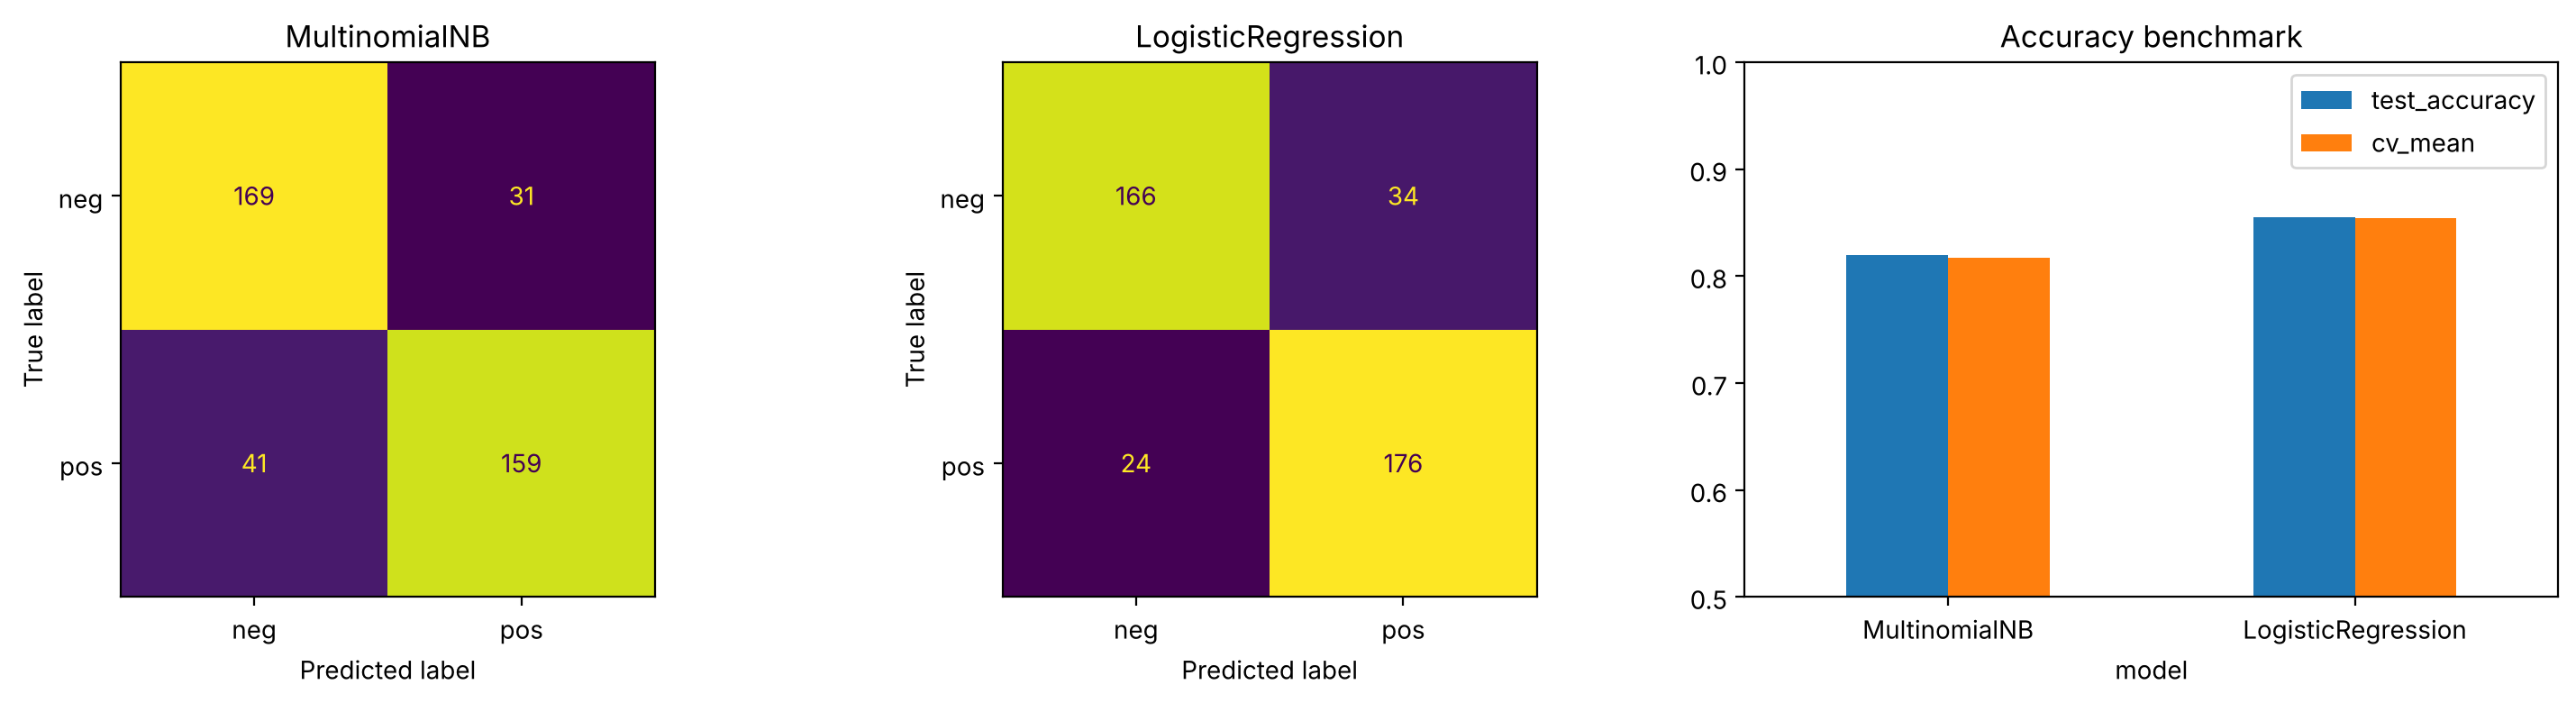

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes[:2], fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)), display_labels=["neg","pos"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
results.set_index("model")[["test_accuracy","cv_mean"]].plot.bar(ax=axes[2], ylim=(0.5,1), rot=0)
axes[2].set_title("Accuracy benchmark"); plt.tight_layout(); plt.show()

### Which words drive the predictions? (Logistic Regression coefficients)

In [8]:
lr = fitted["LogisticRegression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_[0]
top = pd.DataFrame({"most_negative": vocab[np.argsort(coef)[:15]], "most_positive": vocab[np.argsort(coef)[-15:][::-1]]})
top

,most_negative,most_positive
0,bad,great
1,bore,well
2,suppose,see
3,worst,performance
4,plot,fun
5,waste,also
6,nothing,overall
7,no,matrix
8,unfortunately,excellent
9,attempt,perfect


## 5. `predict_sentiment()` — interactive test helper
Domain note: the model is trained on **movie reviews**, so it works best on review-style language. For product reviews, retrain on your own product data by swapping the dataframe in section 4.

In [9]:
def predict_sentiment(text, model="LogisticRegression", verbose=True):
    pipe = fitted[model]
    proba = pipe.predict_proba([preprocess(text)])[0]
    label = "positive" if proba[1] >= 0.5 else "negative"
    if verbose:
        print(f"[{model}] {label.upper():8s} (confidence {max(proba):.1%})  <- {text!r}")
    return label, float(max(proba))

tests = ["Absolutely love this, works flawlessly and great value!",
         "Terrible. Stopped working after two days, very disappointed.",
         "Not worth the money, a boring and awful experience.",
         "A brilliant, moving film with superb acting."]
for t in tests:
    for m in fitted: predict_sentiment(t, m)
    print()

[MultinomialNB] NEGATIVE (confidence 52.5%)  <- 'Absolutely love this, works flawlessly and great value!'
[LogisticRegression] POSITIVE (confidence 75.6%)  <- 'Absolutely love this, works flawlessly and great value!'

[MultinomialNB] NEGATIVE (confidence 64.4%)  <- 'Terrible. Stopped working after two days, very disappointed.'
[LogisticRegression] NEGATIVE (confidence 81.0%)  <- 'Terrible. Stopped working after two days, very disappointed.'

[MultinomialNB] NEGATIVE (confidence 75.3%)  <- 'Not worth the money, a boring and awful experience.'
[LogisticRegression] NEGATIVE (confidence 96.5%)  <- 'Not worth the money, a boring and awful experience.'

[MultinomialNB] POSITIVE (confidence 69.5%)  <- 'A brilliant, moving film with superb acting.'
[LogisticRegression] POSITIVE (confidence 82.4%)  <- 'A brilliant, moving film with superb acting.'



In [10]:
# Interactive loop — type a review, or 'q' to quit (run this cell and use the input box)
while True:
    txt = input("Enter a review (q to quit): ").strip()
    if txt.lower() in {"q", "quit", ""}: break
    for m in fitted: predict_sentiment(txt, m)

## 6. Notes & limitations
* Neutral reviews are excluded (binary task). To support 3 classes, keep them and train on `sentiment` directly — both models handle multiclass.
* TF-IDF + linear models is a bag-of-words approach: it can't capture sarcasm or context well.
* Naive Bayes and Logistic Regression typically land within a few points of each other on this dataset; check the table in section 4 for the actual figures from your run.
* Possible improvements: bigger/in-domain data, `GridSearchCV` over `alpha`/`C`, char n-grams, or a transformer model.